In [6]:
import pandas as pd
import json

timestamps = []

with open("examples/data/Trends-T.json", "r") as file:
    for l in file:
        item = json.loads(l)
        timestamp = item.get("ts", None)
        # Convert to datetime if needed
        if timestamp is not None:
            timestamp = pd.to_datetime(timestamp, unit='s')  # Assuming timestamp is in seconds
        timestamps.append(timestamp)

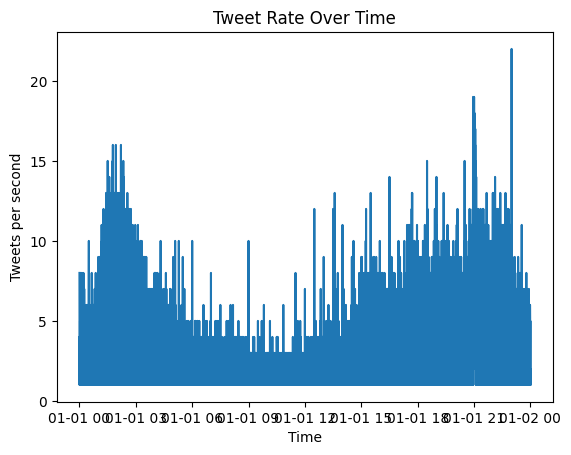

In [15]:
# Meassure tweets per second
s = pd.Series(1, index=timestamps)

rolling_rate = s.rolling("1s").sum().groupby(s.index).last().fillna(0)

import seaborn as sns
import matplotlib.pyplot as plt

sns.lineplot(data=rolling_rate)
plt.xlabel("Time")
plt.ylabel("Tweets per second")
plt.title("Tweet Rate Over Time")
plt.show()


In [14]:
import numpy as np
import pandas as pd
import glob
import seaborn as sns
import matplotlib.pyplot as plt

# Find all files that end with comparison_results.csv
files = glob.glob("experiments/results/*comparison_results.csv", recursive=True)

results = []

for f in files:
    df = pd.read_csv(f)
    results.append(df)
    
df = pd.concat(results, ignore_index=True)

df["dataset"] = df["dataset"].str.replace(".json", "")
df["dataset"] = df["dataset"].str.replace("examples/data/", "")

df

,algorithm,duration,median_num_macroclusters,median_v_meassure,median_homogeneity,median_completeness,median_v_meassure_final,median_homogeneity_final,median_completeness_final,dataset
0,textClust,12.975140,8.0,0.000000,1.000000,0.000000,0.000000,1.000000,0.000000,Semantic5-T_sorted
1,embClust,231.538689,3.0,0.000000,1.000000,0.000000,0.000000,1.000000,0.000000,Semantic5-T_sorted
2,fastLogClust,11.818877,8.0,0.000000,1.000000,0.000000,0.000000,1.000000,0.000000,Semantic5-T_sorted
3,fastClust,8.476655,8.0,0.000000,1.000000,0.000000,0.000000,1.000000,0.000000,Semantic5-T_sorted
4,textClust,7513.390696,108.0,0.797268,0.669444,0.984362,0.797268,0.669444,0.984462,NTSO-T
5,embClust,652.374528,59.0,0.700226,0.547585,0.969819,0.408272,0.259079,0.967713,NTSO-T
6,fastLogClust,2633.682379,113.0,0.801612,0.675205,0.984153,0.801612,0.675059,0.984213,NTSO-T
7,fastClust,1072.577076,78.0,0.767528,0.627454,0.979128,0.645014,0.479129,0.978980,NTSO-T
8,textClust,6659.205040,8.0,0.671411,0.880667,0.612675,0.671411,0.879236,0.689387,Trends-T_modified
9,embClust,532.186489,16.0,0.598778,0.875777,0.479773,0.702708,0.854333,0.664440,Trends-T_modified


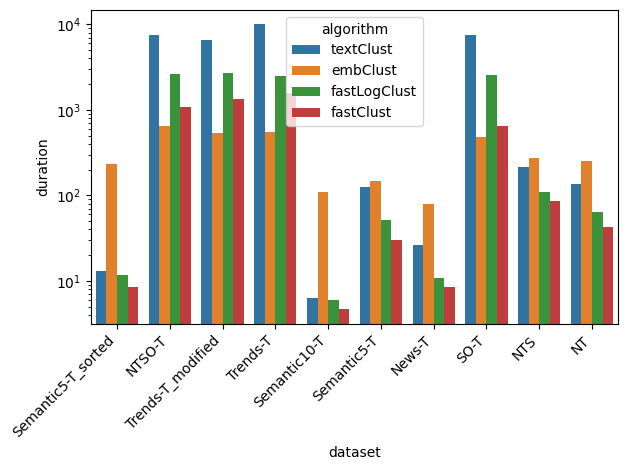

In [16]:
sns.barplot(data=df, hue="algorithm", y="duration", x="dataset")
#Rotate labels and place 
plt.xticks(rotation=45, ha='right')
plt.tight_layout()

#Set log scale for y-axis
plt.yscale("log")

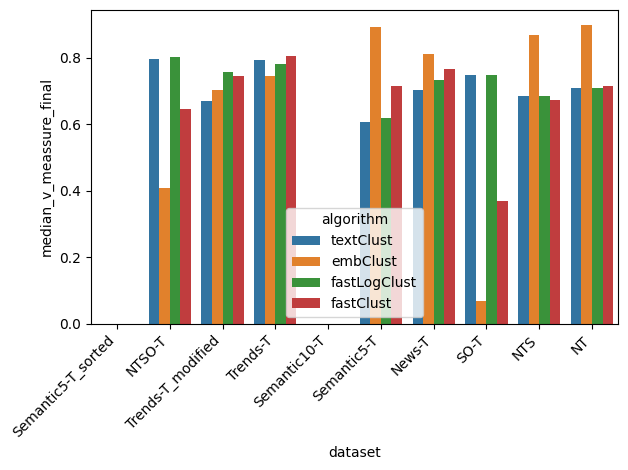

In [19]:
sns.barplot(data=df, hue="algorithm", y="median_v_meassure_final", x="dataset")
#Rotate labels and place 
plt.xticks(rotation=45, ha='right')
plt.tight_layout()

<Axes: xlabel='median_num_macroclusters', ylabel='duration'>

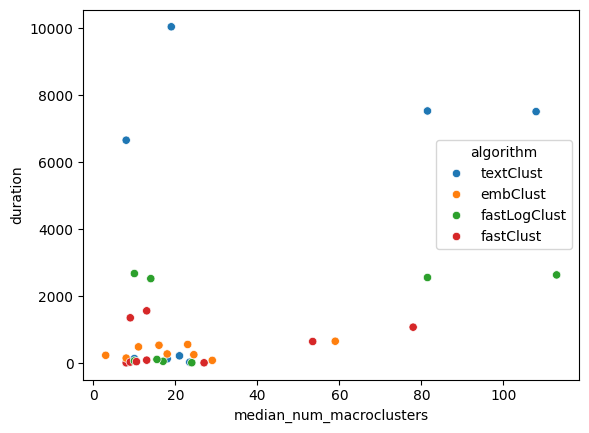

In [17]:
sns.scatterplot(data=df, hue="algorithm", y="duration", x="median_num_macroclusters")